# 04 · Prediction model and refresh rule
**Questions:** can we warn a buyer 3 days *before* an ad fatigues, and how much money would a simple refresh rule have saved?

## Part A · Will this healthy ad fatigue in the next 3 days?
Train/test split is **by date** (train before 1 Sep 2026, test after), so the model never learns from the future.

In [1]:
# cell 1: load and keep only rows with a usable target
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"
df = pd.read_csv(ROOT / "data/processed/ad_daily_features.csv", parse_dates=["date"])
data = df.dropna(subset=["fatigues_next_3d"]).copy()
data["ctr_slope_3d"] = data["ctr_slope_3d"].fillna(0)     # first 3 days have no slope yet
print(len(data), "rows |", f"{data['fatigues_next_3d'].mean():.0%} positive")

NUMERIC = ["days_live", "frequency", "pct_drop_from_peak", "ctr_slope_3d", "cpm_vs_launch"]
CATEGORICAL = ["format", "hook_type"]
TARGET = "fatigues_next_3d"

1613 rows | 19% positive


In [2]:
# cell 2: split by DATE, not randomly
cutoff = pd.Timestamp("2026-09-01")
train, test = data[data["date"] < cutoff], data[data["date"] >= cutoff]
X_train, y_train = train[NUMERIC + CATEGORICAL], train[TARGET].astype(int)
X_test, y_test = test[NUMERIC + CATEGORICAL], test[TARGET].astype(int)
print(f"train: {len(train)} rows (before {cutoff.date()}) | test: {len(test)} rows")

prep = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

train: 1198 rows (before 2026-09-01) | test: 415 rows


In [3]:
# cell 3: model 1, logistic regression (the simple baseline)
logreg = Pipeline([("prep", prep),
                   ("model", LogisticRegression(class_weight="balanced", max_iter=1000))])
logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
print("Logistic regression  ROC-AUC:", round(roc_auc_score(y_test, p_lr), 3))
print(classification_report(y_test, p_lr >= 0.5, digits=2))

Logistic regression  ROC-AUC: 0.907
              precision    recall  f1-score   support

           0       0.95      0.78      0.86       309
           1       0.58      0.89      0.70       106

    accuracy                           0.81       415
   macro avg       0.77      0.83      0.78       415
weighted avg       0.86      0.81      0.82       415



In [4]:
# cell 4: model 2, random forest
forest = Pipeline([("prep", prep),
                   ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                    class_weight="balanced", random_state=42))])
forest.fit(X_train, y_train)
p_rf = forest.predict_proba(X_test)[:, 1]
print("Random forest        ROC-AUC:", round(roc_auc_score(y_test, p_rf), 3))
print(classification_report(y_test, p_rf >= 0.5, digits=2))
print(confusion_matrix(y_test, p_rf >= 0.5))   # rows = actual 0/1, columns = predicted 0/1

Random forest        ROC-AUC: 0.91
              precision    recall  f1-score   support

           0       0.94      0.83      0.88       309
           1       0.63      0.84      0.72       106

    accuracy                           0.83       415
   macro avg       0.78      0.84      0.80       415
weighted avg       0.86      0.83      0.84       415

[[257  52]
 [ 17  89]]


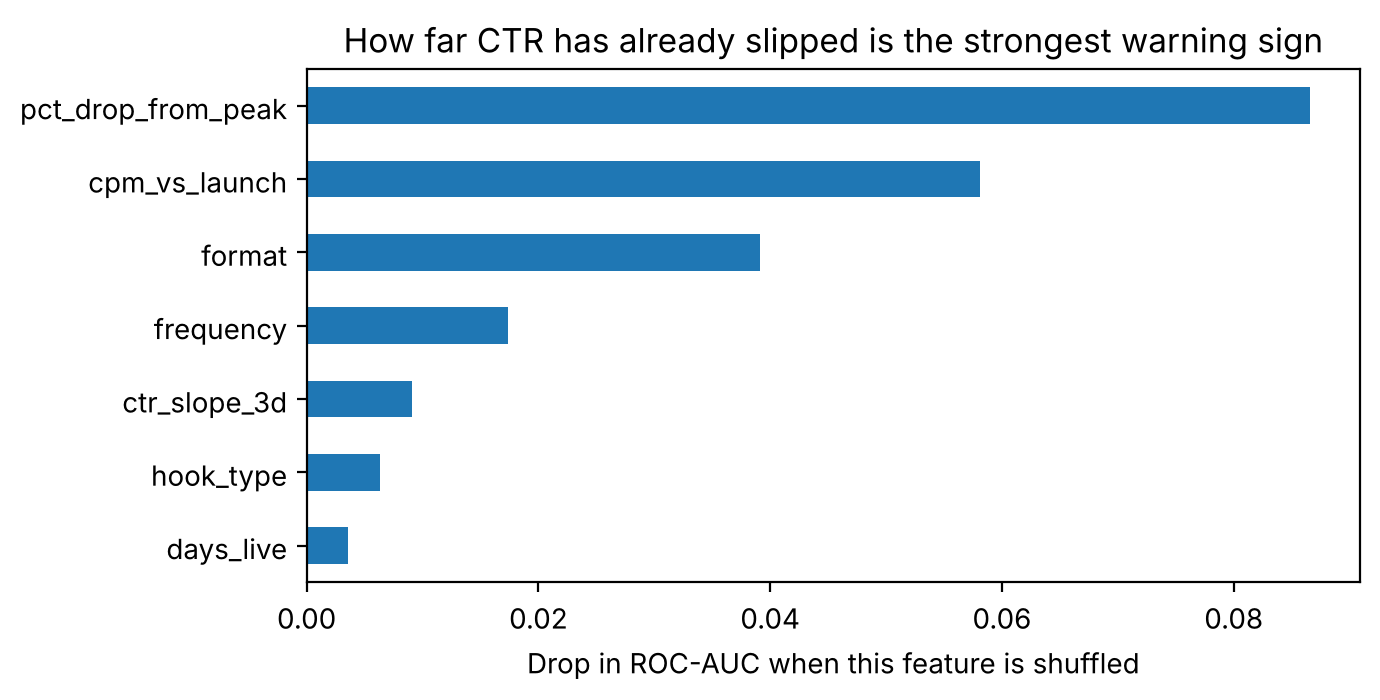

In [5]:
# cell 5: which features matter? (shuffle each one and see how much AUC drops)
imp = permutation_importance(forest, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=42)
importance = pd.Series(imp.importances_mean, index=NUMERIC + CATEGORICAL).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
importance.plot.barh(ax=ax)
ax.set_xlabel("Drop in ROC-AUC when this feature is shuffled")
ax.set_title("How far CTR has already slipped is the strongest warning sign")
plt.tight_layout(); plt.savefig(FIG / "model_feature_importance.png", dpi=150); plt.show()

**So what:** both models reach ROC-AUC ≈ 0.91. Logistic regression catches 89% of ads that go on to fatigue (precision 58%); the random forest catches 84% (precision 63%). The simpler, explainable logistic regression is as good, so the dashboard uses it.

The strongest warning signs are how far CTR has already slipped from its peak, rising CPM and the format.

*Limitation:* the same ad can appear in both train and test; a stricter test would also split by ad.

## Part B · Refresh rule and money saved
**Rule:** refresh an ad the morning after its 3-day CTR has stayed 25% below its own peak for 3 days in a row.

**Extra cost** = spend after detection − (purchases after detection × the ad's healthy CPA). Late purchases still count; we only measure what was overpaid.

In [6]:
# cell 1: load
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data/processed/ad_daily_features.csv", parse_dates=["date"])
df = df.sort_values(["ad_id", "date"])

In [7]:
# cell 2: the same fatigue rule as the SQL, with the threshold as a parameter
def detect_day_per_ad(df, threshold):
    """days_live on which a buyer would KNOW the ad is fatigued (3rd drop day in a row)."""
    drop = ((df["pct_drop_from_peak"] >= threshold) & (df["days_live"] >= 3)).astype(int)
    streak = drop.groupby(df["ad_id"]).rolling(3).sum().reset_index(level=0, drop=True)
    return df.loc[streak == 3].groupby("ad_id")["days_live"].min()

In [8]:
# cell 3: what would refreshing after the detect day have saved?
def evaluate_rule(df, threshold):
    detect = detect_day_per_ad(df, threshold).rename("detect_day")
    d = df.merge(detect, on="ad_id", how="left")
    after = d["detect_day"].notna() & (d["days_live"] > d["detect_day"])
    before = ~after

    # each ad's cost per purchase while it was still healthy
    healthy = d[before].groupby("ad_id")[["spend_inr", "purchases"]].sum()
    healthy_cpa = (healthy["spend_inr"] / healthy["purchases"]).rename("healthy_cpa")

    late = d[after].groupby("ad_id")[["spend_inr", "purchases"]].sum().join(healthy_cpa)
    late["extra_cost"] = late["spend_inr"] - late["purchases"] * late["healthy_cpa"]

    return {
        "threshold": f"{threshold:.0%}",
        "ads_flagged": int(detect.notna().sum()),
        "median_detect_day": float(detect.median()),
        "spend_after_detect_inr": round(late["spend_inr"].sum()),
        "purchases_after_detect": int(late["purchases"].sum()),
        "cpa_healthy_inr": round(d.loc[before, "spend_inr"].sum() / d.loc[before, "purchases"].sum()),
        "cpa_after_detect_inr": round(late["spend_inr"].sum() / late["purchases"].sum()),
        "extra_cost_inr": round(late["extra_cost"].sum()),
    }

In [9]:
# cell 4: sensitivity check
results = pd.DataFrame([evaluate_rule(df, t) for t in [0.15, 0.25, 0.35]])
total = df["spend_inr"].sum()
results["extra_cost_share_of_spend"] = (results["extra_cost_inr"] / total).map("{:.1%}".format)
results.to_csv(ROOT / "reports" / "rule_sensitivity.csv", index=False)
results.T

,0,1,2
threshold,15%,25%,35%
ads_flagged,102,100,92
median_detect_day,14.0,16.0,17.5
spend_after_detect_inr,2781764,2196832,1556615
purchases_after_detect,4637,3292,2012
cpa_healthy_inr,253,261,272
cpa_after_detect_inr,600,667,774
extra_cost_inr,1573337,1344607,1025223
extra_cost_share_of_spend,16.5%,14.1%,10.8%


**So what:** at the 25% rule, buyers paid about **₹13.4 lakh (14% of total spend)** more than healthy CPA. After fatigue, each purchase cost about 2.5× more (₹261 → ₹667).

**Sensitivity:** an earlier 15% trigger saves more on this data, but simulated ads never recover once they decay. Real ads sometimes bounce back, so 25% is the recommended default until it is tuned on a real export.